# Phase 1 Proper — Forgetting-Aware Rank-Adaptive Fine-Tuning: LoRA

**Notebook:** `02_phase1_lora_proper.ipynb`
**Mode:** PHASE 1 PROPER (first run) — this is the first full-scale Phase 1
run, using settings chosen after the smoke test (`01_phase1_lora.ipynb`)
confirmed the pipeline works end-to-end. It produces the first real Phase 1
LoRA-vs-forgetting numbers for this project.

**This is still a single run with a single seed.** Per the project's
scientific rules, no conclusion about "does LoRA forget" should be drawn
from one run — this notebook does not claim statistical significance, and
neither should any reading of its output. Multi-seed / multi-size sweeps are
future work, not part of this notebook.

**Smoke test results this run builds on** (from `01_phase1_lora.ipynb`,
100 train / 50 probe examples, 1 epoch): BoolQ 0.70→0.66 (gap +0.04), PIQA
0.68→0.70 (gap −0.02), SAMSum ROUGE-L 0.2962→0.3294, trainable params
4,399,104 / 498,431,872 (0.8826%), training ~34s, peak GPU memory ~4.9GB.
Those numbers are too small-sample to mean anything on their own — this
notebook exists to get a more meaningful (still single-run) version of them.

## What this project is (from `README_anu_van.md`)

We are studying **catastrophic forgetting** during parameter-efficient
fine-tuning (PEFT): when you fine-tune a model on Task A, does it quietly get
worse at unrelated Task B, even though you never trained on B? The full
project (Phase 2/3, not built here) will compare LoRA, AdaLoRA, and DoRA on
this question. Phase 1 proves the measurement pipeline works for **LoRA
alone**.

## The Phase 1 experiment

```
                 BASE QWEN2.5-0.5B
                        |
        +---------------+----------------+
        |               |                |
   SAMSum PRE       BoolQ PRE        PIQA PRE
        |               |                |
        +---------------+----------------+
                        |
                 Attach LoRA adapter
                        |
             Fine-tune ONLY on SAMSum
                        |
                  LoRA-tuned QWEN
                        |
        +---------------+----------------+
        |               |                |
   SAMSum POST      BoolQ POST       PIQA POST
        |               |                |
        +---------------+----------------+
                        |
              SAMSum learning gain  (post - pre ROUGE)
              BoolQ forgetting gap  (pre - post accuracy)
              PIQA forgetting gap   (pre - post accuracy)
```

**SAMSum** is the *only* dataset we ever train on (dialogue summarization).
**BoolQ** and **PIQA** are *forgetting probes* — zero-shot commonsense/QA
tasks the model is never trained on. We measure them before and after
SAMSum fine-tuning, on the **exact same held-out examples**, to see whether
LoRA fine-tuning quietly degrades unrelated capability.

## Table of contents

1–2. Overview & what we're testing &nbsp;•&nbsp; 3. Install deps &nbsp;•&nbsp;
4. Imports &nbsp;•&nbsp; 5. Configuration &nbsp;•&nbsp; 6. GPU/environment check &nbsp;•&nbsp;
7. Seeds &nbsp;•&nbsp; 8. Output dir / Drive &nbsp;•&nbsp; 9. Load datasets &nbsp;•&nbsp;
10. Inspect samples &nbsp;•&nbsp; 11. Load base model &nbsp;•&nbsp;
12. Log-likelihood scoring fn &nbsp;•&nbsp; 13. BoolQ eval fn &nbsp;•&nbsp;
14. PIQA eval fn &nbsp;•&nbsp; 15. SAMSum prompt/tokenize/generate/ROUGE fns &nbsp;•&nbsp;
16. Freeze fixed eval samples &nbsp;•&nbsp; 17–19. PRE evaluation (BoolQ, PIQA, SAMSum) &nbsp;•&nbsp;
20. Baseline results &nbsp;•&nbsp; 21. Configure LoRA &nbsp;•&nbsp;
22. Trainable parameters &nbsp;•&nbsp; 23. Prepare SAMSum training data &nbsp;•&nbsp;
24. Fine-tune &nbsp;•&nbsp; 25. Save adapter &nbsp;•&nbsp; 26. Reload adapter &nbsp;•&nbsp;
27. POST SAMSum eval + qualitative examples &nbsp;•&nbsp; 28–29. POST BoolQ/PIQA &nbsp;•&nbsp;
30. Forgetting gaps & learning gain &nbsp;•&nbsp; 31. Results table &nbsp;•&nbsp;
32. Plot &nbsp;•&nbsp; 33. Save results &nbsp;•&nbsp; 34. Interpretation & limitations

**Methodology carried over unchanged from the smoke test** (this notebook
only scales up sample sizes / training settings — see Section 05 and the
"What changed from the smoke test" note there): base checkpoint
`Qwen/Qwen2.5-0.5B`; BoolQ question text used verbatim (no appended `?`);
PIQA uses length-normalized log-likelihood with the exact formula documented
in Section 14 (not claimed to match any external benchmark implementation);
target-only loss for SAMSum; LoRA target modules `q_proj, k_proj, v_proj,
o_proj, gate_proj, up_proj, down_proj` recorded in every result row; SAMSum
is evaluated PRE *and* POST fine-tuning. AdaLoRA and DoRA are explicitly
**out of scope** for this notebook — Phase 1 covers LoRA only.


## 02. What We Are Testing

**Independent variable:** whether LoRA fine-tuning on SAMSum has happened yet
(pre vs. post).

**Dependent variables:**
- SAMSum ROUGE-1/2/L (did the model learn the target task?)
- BoolQ accuracy (did it forget general yes/no reasoning?)
- PIQA accuracy (did it forget physical commonsense reasoning?)

**Key terminology:**
- **PEFT (Parameter-Efficient Fine-Tuning):** fine-tuning a small number of
  added parameters while freezing the pretrained model, instead of updating
  all weights.
- **LoRA (Low-Rank Adaptation):** a PEFT method that injects small trainable
  low-rank matrices (`A`, `B`) alongside frozen weight matrices, so the
  effective update is `W + (alpha/r) * B @ A` instead of a full `W` update.
- **Catastrophic forgetting:** a model losing previously-held capability as a
  side effect of learning something new.
- **Zero-shot probing:** evaluating a capability the model was never trained
  for in this pipeline, using only its pretrained knowledge.
- **Forgetting gap:** `pre-fine-tuning probe accuracy − post-fine-tuning
  probe accuracy`. Positive = forgot something. ~0 = no measured change.
  Negative = probe score improved (also worth reporting, not just positive
  gaps).

**What "success" looks like for THIS run:** every stage executes without
error and produces a saved result record with 2,000 SAMSum training examples
and 500-example BoolQ/PIQA probes — large enough to be a meaningful first
Phase 1 data point, but still **one run with one seed**. A larger/positive/
negative forgetting gap here is one observation, not a finding; it becomes a
finding only after the multi-seed sweep planned for later (see README
Week 2, day 9), which this notebook does not perform.


## 03. Install Dependencies

Colab ships with PyTorch pre-installed (we deliberately do not reinstall or
pin `torch` itself — Colab's preinstalled build is matched to the notebook's
CUDA runtime, and reinstalling it via pip risks breaking that match). We
additionally need Hugging Face `transformers`, `datasets`, `peft`,
`accelerate` (for `Trainer`), and `evaluate` + `rouge_score` (for ROUGE
metrics on SAMSum).

**`torchao` compatibility note.** `torchao` is an *optional* PEFT dependency
used only for quantization-aware LoRA (e.g. int8/int4 base-model weights via
`TorchAoConfig`). Phase 1 does not use quantization at all (see the design
doc), so `torchao` provides nothing we need. Google Colab's base image
currently ships a **preinstalled `torchao` (e.g. 0.10.0)** that predates the
minimum version (`>=0.16.0`) newer `peft` releases check for. Because our
install command above only adds/upgrades the packages we actually list, that
stale preinstalled `torchao` is otherwise left untouched — and current
`peft` validates any *present* `torchao` installation's version even though
we never invoke torchao functionality, so `get_peft_model()` fails with
`ImportError: Found an incompatible version of torchao`. Since we don't need
`torchao`'s functionality, the cleanest fix is to remove it rather than
upgrade it: an absent optional dependency is skipped entirely by PEFT's
internal `is_torchao_available()` check, so the version-gate code path never
runs.


In [3]:
!pip install -q -U "transformers>=4.44" "datasets>=2.19" "peft>=0.11" accelerate evaluate rouge_score

# torchao is not required for standard (non-quantized) LoRA -- see markdown
# above. Uninstalling Colab's preinstalled, version-incompatible copy avoids
# a spurious ImportError from PEFT's optional torchao integration.
!pip uninstall -y -q torchao


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.4 MB/s eta 0:00:00


**IMPORTANT -- restart the Colab runtime now.** The cell above changed
installed package versions (upgraded `transformers`/`peft`/`accelerate` and
removed `torchao`). Python does not pick up package changes for modules
already imported in the current process, so this will not take effect until
you restart:

**Runtime -> Restart session** (or **Runtime -> Restart runtime** on older
Colab UIs), then re-run this notebook from the top (Section 01 onward). This
restart is needed once per fresh environment / whenever this cell's package
list changes -- not before every run.


## 04. Imports

All imports live in one place so notebook state stays predictable — no
import statements are hidden inside later cells.


In [4]:
import sys
import json
import time
import random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import transformers
import peft
import evaluate as hf_evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, TaskType, PeftModel


def stage(title: str) -> None:
    """Prints a clean stage banner. Used to keep notebook output readable
    without flooding it with unstructured logs."""
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


print("Imports OK.")


Imports OK.


## 05. Configuration

All experiment knobs live in one `Config` object. The values below are the
**approved PHASE 1 PROPER (first run) settings**, chosen after the smoke
test confirmed the pipeline works and gave us a first read on GPU memory
(~4.9GB) and training speed (~34s for 50 steps).

**What changed from the smoke test config** (everything else is identical):

| Setting | Smoke test | Phase 1 Proper |
|---|---|---|
| `samsum_train_samples` | 100 | **2,000** |
| `samsum_eval_samples` | 20 | **200** |
| `samsum_max_length` | 256 | **512** |
| `boolq_probe_samples` | 50 | **500** |
| `piqa_probe_samples` | 50 | **500** |
| `epochs` | 1 | **2** |
| `per_device_train_batch_size` | 2 | **4** |
| `gradient_accumulation_steps` | 1 | **4** |
| `smoke_test` / `phase` | `True` / (n/a) | **`False`** / **`"phase1_proper"`** |

`learning_rate` (2e-4) and every LoRA setting (`r=8, alpha=16, dropout=0.05`,
all 7 target modules, `bias="none"`) are **unchanged**, per the approved
scope for this run. `probe_max_length` (BoolQ passage truncation budget) is
also **left at 256, unchanged** — it wasn't part of the requested Phase 1
Proper settings, so it's carried over rather than silently changed; flag
this explicitly if you'd rather it scale with `samsum_max_length`.

**Effective batch size** = `per_device_train_batch_size × gradient_accumulation_steps`
= 4 × 4 = **16** (up from the smoke test's 2 × 1 = 2). This is computed
below and reused everywhere it needs to be logged (training config display,
saved results record).


In [5]:
from dataclasses import dataclass, field
from typing import List


@dataclass
class Config:
    # --- run mode / experiment identity ---
    smoke_test: bool = False
    phase: str = "phase1_proper"
    peft_method: str = "lora"

    # --- reproducibility ---
    seed: int = 42

    # --- base model (approved: base, not Instruct -- see design doc) ---
    base_model_id: str = "Qwen/Qwen2.5-0.5B"

    # --- SAMSum: the ONLY fine-tuning dataset ---
    samsum_train_samples: int = 2000     # PHASE 1 PROPER (first run) size
    samsum_eval_samples: int = 200       # held-out; evaluated PRE and POST
    samsum_max_length: int = 512         # tokens: prompt + summary, combined
    samsum_gen_max_new_tokens: int = 64  # generation budget for summaries

    # --- BoolQ / PIQA: forgetting probes, NEVER trained on ---
    boolq_probe_samples: int = 500
    piqa_probe_samples: int = 500
    probe_max_length: int = 256          # unchanged from smoke test (see markdown above)

    # --- LoRA (unchanged from smoke test) ---
    lora_r: int = 8
    lora_alpha: int = 16
    lora_dropout: float = 0.05
    lora_target_modules: List[str] = field(default_factory=lambda: [
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ])
    lora_bias: str = "none"

    # --- training (PHASE 1 PROPER, first run) ---
    epochs: int = 2
    per_device_train_batch_size: int = 4
    gradient_accumulation_steps: int = 4
    learning_rate: float = 2e-4


config = Config()
effective_batch_size = config.per_device_train_batch_size * config.gradient_accumulation_steps

for k, v in config.__dict__.items():
    print(f"{k:28s}: {v}")
print(f"{'effective_batch_size':28s}: {effective_batch_size}  (= per_device_train_batch_size * gradient_accumulation_steps)")


smoke_test                  : False
phase                       : phase1_proper
peft_method                 : lora
seed                        : 42
base_model_id               : Qwen/Qwen2.5-0.5B
samsum_train_samples        : 2000
samsum_eval_samples         : 200
samsum_max_length           : 512
samsum_gen_max_new_tokens   : 64
boolq_probe_samples         : 500
piqa_probe_samples          : 500
probe_max_length            : 256
lora_r                      : 8
lora_alpha                  : 16
lora_dropout                : 0.05
lora_target_modules         : ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
lora_bias                   : none
epochs                      : 2
per_device_train_batch_size : 4
gradient_accumulation_steps : 4
learning_rate               : 0.0002
effective_batch_size        : 16  (= per_device_train_batch_size * gradient_accumulation_steps)


## 06. Check GPU / Environment

We print versions of every library that affects reproducibility, and detect
CUDA + precision support automatically. **T4 GPUs (Turing architecture) do
not have accelerated bf16 tensor cores** — only Ampere-or-newer GPUs (A100,
L4, RTX 30xx+) do — so we auto-select fp16 on T4 and bf16 only where
actually supported, rather than assuming bf16 works everywhere.

If no GPU is detected, this cell prints a loud warning before any training
happens.


In [6]:
stage("Environment check")

print(f"Python version      : {sys.version.split()[0]}")
print(f"PyTorch version      : {torch.__version__}")
print(f"Transformers version : {transformers.__version__}")
print(f"PEFT version         : {peft.__version__}")

# This project does not use quantization, so torchao is not required.
# We only check it here to fail fast with a clear message (pointing back to
# Section 03's install cell) instead of a confusing ImportError deep inside
# get_peft_model() later.
try:
    import torchao
    from packaging import version as _pkg_version
    torchao_ok = _pkg_version.parse(torchao.__version__) >= _pkg_version.parse("0.16.0")
    print(f"torchao version      : {torchao.__version__} (present, but NOT required by this project)")
    if not torchao_ok:
        print("*** WARNING: an old, incompatible torchao is installed and may break get_peft_model().")
        print("*** Re-run Section 03's install cell (which uninstalls torchao) and RESTART THE RUNTIME.")
except ImportError:
    print("torchao version      : not installed (expected -- this project uses standard, non-quantized LoRA)")

cuda_available = torch.cuda.is_available()
print(f"CUDA available       : {cuda_available}")

if cuda_available:
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU                  : {gpu_name}")
    print(f"Total GPU VRAM       : {total_vram_gb:.1f} GB")

    use_bf16 = torch.cuda.is_bf16_supported()
    use_fp16 = not use_bf16
    print(f"bf16 supported       : {use_bf16}  -> training precision: {'bf16' if use_bf16 else 'fp16'}")
else:
    device = torch.device("cpu")
    use_bf16 = False
    use_fp16 = False
    print()
    print("*** WARNING: No GPU detected. Training will run on CPU and will be slow.")
    print("*** In Colab: Runtime -> Change runtime type -> Hardware accelerator -> GPU (T4).")
    print("*** Proceeding anyway, but this Phase 1 Proper run REQUIRES a GPU to finish in reasonable time.")

print(f"\nSelected device      : {device}")



Environment check
Python version      : 3.12.13
PyTorch version      : 2.11.0+cu128
Transformers version : 5.15.0
PEFT version         : 0.20.0
torchao version      : not installed (expected -- this project uses standard, non-quantized LoRA)
CUDA available       : True
GPU                  : Tesla T4
Total GPU VRAM       : 14.6 GB
bf16 supported       : True  -> training precision: bf16

Selected device      : cuda


## 07. Reproducibility / Random Seeds

One function seeds every source of randomness we use: Python's `random`,
NumPy, PyTorch (CPU and all CUDA devices), and `transformers`' own seeding
utility. Called once, immediately, before any sampling or model
initialization happens.

Note: GPU floating-point operations are not perfectly bit-reproducible
across runs/hardware even with seeds fixed (e.g. nondeterministic reduction
order in some CUDA kernels) — seeding controls the *major* stochastic
sources (sampling, initialization, shuffling), not bit-exact reproducibility.


In [7]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)


set_seed(config.seed)
print(f"Seed set to {config.seed} for random, numpy, torch, cuda, and transformers.")


Seed set to 42 for random, numpy, torch, cuda, and transformers.


## 08. Output Directory & Optional Google Drive

Everything we save (LoRA adapters, evaluation indices, result records) goes
under one configurable `OUTPUT_ROOT`. By default this is local Colab
storage, which is wiped when the runtime disconnects. Set `USE_DRIVE = True`
and re-run this cell for persistent storage across sessions.

No personal Drive path is hardcoded anywhere else in the notebook — every
other cell reads from `OUTPUT_ROOT` and its subfolders.

**Important, Phase-1-Proper-specific:** fixed evaluation indices
(`sample_fixed_indices`, Section 16) are loaded from disk if a file already
exists at the target path, and this notebook shares `OUTPUT_ROOT` with the
smoke test if you point both at the same Drive folder. If Phase 1 Proper
wrote its 500-example BoolQ/PIQA indices to the *same filenames* the smoke
test used for its 50-example indices, this run would silently reuse the tiny
smoke-test sample instead of drawing a new 500-example one. To make that
impossible, this notebook keeps its fixed indices in a **separate
`indices/phase1_proper/` subfolder**, so it can never collide with the smoke
test's `indices/*.json` files even when `OUTPUT_ROOT` is shared.


In [8]:
USE_DRIVE = False  # set True and re-run this cell for persistent Google Drive storage

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/forgetting-aware-peft/outputs')
else:
    # Falls back to a local ./outputs folder if not running inside Colab
    # (e.g. when the notebook is opened elsewhere), so the notebook doesn't
    # crash trying to create a top-level /content directory.
    OUTPUT_ROOT = Path('/content/outputs') if Path('/content').exists() else Path('./outputs')

ADAPTER_DIR = OUTPUT_ROOT / "adapters"
RESULTS_DIR = OUTPUT_ROOT / "results"
# Phase-specific subfolder: keeps this run's 500/500/200-example fixed
# indices from ever colliding with (or being silently reused from) the
# smoke test's 50/50/20-example indices, even if OUTPUT_ROOT is shared.
INDICES_DIR = OUTPUT_ROOT / "indices" / config.phase

for d in (ADAPTER_DIR, RESULTS_DIR, INDICES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"OUTPUT_ROOT = {OUTPUT_ROOT.resolve()}")


OUTPUT_ROOT = /content/outputs


## 09. Load Datasets

Three datasets, three different roles — **this distinction must never be
violated**:

| Dataset | Role | Ever trained on? |
|---|---|---|
| SAMSum | fine-tuning target (dialogue summarization) | **Yes** |
| BoolQ | forgetting probe (yes/no reading comprehension) | **Never** |
| PIQA | forgetting probe (physical commonsense QA) | **Never** |

**Known risk:** the original `samsum` and `piqa` loading scripts on the HF
Hub are older-style "loading script" datasets, which recent versions of
`datasets` refuse to load at all (`RuntimeError: Dataset scripts are no
longer supported`) — `trust_remote_code` does not help, because the library
has removed script execution entirely, not just gated it behind a flag. We
try a short list of known-good candidate sources for each dataset, in order,
and print + record whichever one actually succeeded — so the exact data
provenance is never ambiguous, and a single broken mirror doesn't silently
break the whole notebook.

**PIQA source, confirmed by hand before wiring it in here:** both `piqa` and
`ybisk/piqa` are script-based and fail under current `datasets` versions.
`lighteval/piqa` is a script-free Parquet mirror (verified via the HF
datasets-server API: repo contains only `.parquet` files, no `.py` script)
with splits `train=16113`, `validation=1838`, `test=3084` — matching the
official PIQA benchmark sizes exactly. Its `validation` split has columns
`goal, sol1, sol2, label` with `label` as a 0/1 `ClassLabel`; spot-checked
rows confirm **`label == 0` means `sol1` is the correct solution and
`label == 1` means `sol2` is correct** (e.g. the guinea-pig-cage example:
`sol1` describes correct bedding material, `label == 0`). This is exactly
the mapping this notebook's `evaluate_piqa` already assumes
(`predicted = 0 if sol1_avg > sol2_avg else 1`, compared to `gold =
int(ex["label"])`), so no scoring logic needed to change. The `test` split
is confirmed unlabeled (`label == -1` for all rows, held out for the
official leaderboard) — consistent with why we evaluate on `validation`,
never `test`, for the PIQA probe.


In [9]:
stage("Loading datasets")


def _try_load_dataset(name: str):
    """Try loading `name` normally; if that fails, retry once with
    trust_remote_code=True (needed for some older script-based datasets).
    Some newer `datasets` versions don't accept that kwarg at all, so we
    fall through cleanly if it errors too."""
    try:
        return load_dataset(name)
    except Exception:
        return load_dataset(name, trust_remote_code=True)


def load_dataset_with_fallback(candidates, task_name):
    last_error = None
    for name in candidates:
        try:
            ds = _try_load_dataset(name)
            print(f"Loaded {task_name} from '{name}'")
            return ds, name
        except Exception as e:
            last_error = e
            print(f"  could not load {task_name} from '{name}': {type(e).__name__}: {e}")
    raise RuntimeError(
        f"Failed to load {task_name} from any candidate source {candidates}. "
        f"Last error: {last_error}"
    )


def _assert_columns(dataset_split, required_columns, task_name):
    missing = [c for c in required_columns if c not in dataset_split.column_names]
    if missing:
        raise ValueError(
            f"{task_name} dataset is missing expected column(s) {missing}. "
            f"Found columns: {dataset_split.column_names}. The loaded source "
            f"may use a different schema than expected -- inspect and adjust the code."
        )


samsum_ds, samsum_source = load_dataset_with_fallback(
    ["samsum", "knkarthick/samsum", "Samsung/samsum"], "SAMSum"
)
boolq_ds, boolq_source = load_dataset_with_fallback(
    ["google/boolq", "boolq"], "BoolQ"
)
piqa_ds, piqa_source = load_dataset_with_fallback(
    ["lighteval/piqa"], "PIQA"
)

_assert_columns(samsum_ds["train"], ["dialogue", "summary"], "SAMSum")
_assert_columns(boolq_ds["validation"], ["question", "answer", "passage"], "BoolQ")
_assert_columns(piqa_ds["validation"], ["goal", "sol1", "sol2", "label"], "PIQA")

print("\nDataset sources actually used (recorded later in the results record):")
print(f"  SAMSum: {samsum_source}  (splits: {list(samsum_ds.keys())})")
print(f"  BoolQ : {boolq_source}  (splits: {list(boolq_ds.keys())})")
print(f"  PIQA  : {piqa_source}  (splits: {list(piqa_ds.keys())})")



Loading datasets


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'samsum' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'samsum' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  could not load SAMSum from 'samsum': DatasetNotFoundError: Dataset 'samsum' doesn't exist on the Hub or cannot be accessed.


README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

...

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16113 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3084 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1838 [00:00<?, ? examples/s]

Loaded PIQA from 'lighteval/piqa'

Dataset sources actually used (recorded later in the results record):
  SAMSum: knkarthick/samsum  (splits: ['train', 'validation', 'test'])
  BoolQ : google/boolq  (splits: ['train', 'validation'])
  PIQA  : lighteval/piqa  (splits: ['train', 'test', 'validation'])


## 10. Understand BoolQ / PIQA / SAMSum Samples

Before building prompts, look at one raw example from each dataset so the
prompt templates in later stages are grounded in what the data actually
looks like.


In [10]:
stage("Sample inspection")

print("=== SAMSum example ===")
ex = samsum_ds["train"][0]
print("Dialogue:\n", ex["dialogue"][:500])
print("\nSummary:\n", ex["summary"])

print("\n=== BoolQ example ===")
ex = boolq_ds["validation"][0]
print("Passage:\n", ex["passage"][:500])
print("\nQuestion:", ex["question"])
print("Answer   :", ex["answer"])

print("\n=== PIQA example ===")
ex = piqa_ds["validation"][0]
print("Goal   :", ex["goal"])
print("Sol 1  :", ex["sol1"])
print("Sol 2  :", ex["sol2"])
print("Label  :", ex["label"], "(0 -> sol1 correct, 1 -> sol2 correct)")



Sample inspection
=== SAMSum example ===
Dialogue:
 Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

Summary:
 Amanda baked cookies and will bring Jerry some tomorrow.

=== BoolQ example ===
Passage:
 All biomass goes through at least some of these steps: it needs to be grown, collected, dried, fermented, distilled, and burned. All of these steps require resources and an infrastructure. The total amount of energy input into the process compared to the energy released by burning the resulting ethanol fuel is known as the energy balance (or ``energy returned on energy invested''). Figures compiled in a 2007 report by National Geographic Magazine point to modest results for corn ethanol produced

Question: does ethanol take more energy make that produces
Answer   : False

=== PIQA example ===
Goal   : How do I ready a guinea pig cage for it's new occupants?
Sol 1  : Provide the guinea pig with a cage full of a few inches of bedding made of rip

## 11. Load Base Qwen Model

We load `Qwen/Qwen2.5-0.5B` — the **base** (not Instruct) checkpoint — see
the approved design decision: starting from base avoids conflating our LoRA
fine-tuning with a prior instruction-tuning/alignment stage, and matches how
log-likelihood zero-shot probing is normally done.

**Precision decision:** we load weights in plain fp32 rather than fp16/bf16.
Mixed precision is applied only *during training* (via `Trainer`), which is
more numerically stable than storing LoRA adapters on top of fp16/bf16 base
weights. At ~0.5B parameters, fp32 weights are only ~2GB — comfortably
within a T4's ~15GB VRAM.

If `tokenizer.pad_token` is missing, we reuse `eos_token` as the pad token
rather than adding a brand-new token, which would otherwise force resizing
the embedding matrix — unnecessary complexity for this project.


In [11]:
stage("Loading base model")

try:
    tokenizer = AutoTokenizer.from_pretrained(config.base_model_id)
    base_model = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
except Exception as e:
    raise RuntimeError(
        f"Failed to load base model/tokenizer '{config.base_model_id}'. "
        f"Check your internet connection and that the checkpoint name is correct. "
        f"Original error: {e}"
    ) from e

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    print(f"tokenizer.pad_token was None -> set to eos_token ({tokenizer.eos_token!r})")
else:
    print(f"tokenizer.pad_token already set: {tokenizer.pad_token!r}")

base_model.to(device)
base_model.eval()

n_params = sum(p.numel() for p in base_model.parameters())
print(f"\nBase model loaded: {config.base_model_id}")
print(f"Total parameters : {n_params:,}")



Loading base model


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

tokenizer.pad_token already set: '<|endoftext|>'

Base model loaded: Qwen/Qwen2.5-0.5B
Total parameters : 494,032,768


## 12. Define Shared Log-Likelihood Scoring Function

Both BoolQ and PIQA are scored with **teacher-forced log-likelihood**, not
free-form `generate()`. Rationale: generation requires parsing arbitrary
text output ("Yes.", "yes", "I believe yes because...") which is fragile and
depends on decoding settings; log-likelihood scoring is deterministic,
needs no decoding parameters, and directly measures "does the model assign
higher probability to the correct answer."

**Tokenization boundary detail (important, easy to get wrong):** we do NOT
tokenize `prompt` and `continuation` separately and concatenate the token
ids. BPE tokenizers can merge tokens differently right at that boundary,
silently producing a different (and wrong) token sequence. Instead we
tokenize `prompt` alone (to find its length in tokens) and `prompt +
continuation` together (as one string), then slice out the continuation's
token ids from the combined tokenization. This is the standard, boundary-safe
approach.

This single function is reused for BoolQ, PIQA, *and* internally is the
same kind of pass used consistently across the whole notebook — one
scoring implementation, never duplicated, so pre/post scoring cannot
silently drift apart from each other.


In [12]:
def continuation_log_likelihood(model, tokenizer, prompt: str, continuation: str, device):
    """
    Returns (sum_log_prob, num_continuation_tokens) for `continuation`
    conditioned on `prompt`, using one teacher-forced forward pass.

    Formula:
        sum_log_prob = sum over continuation tokens t_i of
                        log P(t_i | prompt, t_1, ..., t_{i-1})
    """
    context_ids = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").input_ids[0]
    whole_ids = tokenizer(prompt + continuation, add_special_tokens=False, return_tensors="pt").input_ids[0]
    context_len = context_ids.shape[0]

    if not torch.equal(whole_ids[:context_len], context_ids):
        raise ValueError(
            "Tokenization boundary mismatch between prompt and prompt+continuation. "
            "This usually means the continuation string needs a leading space, or the "
            f"prompt has an unexpected trailing space. prompt={prompt!r} continuation={continuation!r}"
        )

    continuation_ids = whole_ids[context_len:]
    if continuation_ids.shape[0] == 0:
        raise ValueError(f"Continuation tokenized to zero tokens: {continuation!r}")

    input_ids = whole_ids.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(input_ids=input_ids).logits[0]  # (seq_len, vocab_size)
    log_probs = F.log_softmax(logits.float(), dim=-1)

    total_log_prob = 0.0
    for i, tok_id in enumerate(continuation_ids):
        # position (context_len + i - 1) predicts the token at position (context_len + i)
        pred_pos = context_len + i - 1
        total_log_prob += log_probs[pred_pos, tok_id.item()].item()

    return total_log_prob, continuation_ids.shape[0]


print("continuation_log_likelihood() defined.")


continuation_log_likelihood() defined.


## 13. Define BoolQ Evaluation

**Prompt (question text used exactly as provided by the dataset — no
appended "?" or other modification, per approved design change):**

```
Passage:
{passage}

Question:
{question}

Answer:
```

**Scoring:** compute `continuation_log_likelihood` for `" Yes"` and `" No"`
appended to the prompt; predict whichever has the higher summed
log-probability. "Yes"/"No" are both short (typically 1 token each in
Qwen's tokenizer), so no length normalization is needed here — unlike PIQA
below, where the two options can differ substantially in length.

We also report the **majority-class baseline** (always predicting the more
common gold label in the sampled set) alongside model accuracy — BoolQ's
label distribution is naturally skewed toward "True," so a bare accuracy
number is easy to over-read as "reasoning" without this context.

Long passages are truncated deterministically (from the end, at a fixed
token budget) — identically pre- and post-fine-tuning.


In [13]:
BOOLQ_PROMPT_TEMPLATE = (
    "Passage:\n{passage}\n\n"
    "Question:\n{question}\n\n"
    "Answer:"
)


def truncate_to_token_budget(text: str, tokenizer, max_tokens: int) -> str:
    """Deterministically truncate `text` to at most `max_tokens` tokens,
    applied identically PRE and POST fine-tuning."""
    ids = tokenizer(text, add_special_tokens=False).input_ids
    if len(ids) <= max_tokens:
        return text
    return tokenizer.decode(ids[:max_tokens])


def evaluate_boolq(model, tokenizer, examples, device, max_passage_tokens):
    model.eval()
    n_correct = 0
    n_gold_true = 0
    for ex in examples:
        passage = truncate_to_token_budget(ex["passage"], tokenizer, max_passage_tokens)
        # Question text used verbatim -- no added "?" or other modification.
        prompt = BOOLQ_PROMPT_TEMPLATE.format(passage=passage, question=ex["question"])

        yes_lp, _ = continuation_log_likelihood(model, tokenizer, prompt, " Yes", device)
        no_lp, _ = continuation_log_likelihood(model, tokenizer, prompt, " No", device)

        predicted = yes_lp > no_lp
        gold = bool(ex["answer"])
        n_correct += int(predicted == gold)
        n_gold_true += int(gold)

    n = len(examples)
    accuracy = n_correct / n
    majority_class_baseline = max(n_gold_true, n - n_gold_true) / n
    return {
        "accuracy": accuracy,
        "n_examples": n,
        "majority_class_baseline": majority_class_baseline,
    }


print("evaluate_boolq() defined.")


evaluate_boolq() defined.


## 14. Define PIQA Evaluation

**Prompt:**

```
Goal: {goal}
Solution:
```
scored twice — once continued with `" " + sol1`, once with `" " + sol2`.

**Scoring formula (exact, implemented below):**

```
avg_log_prob(solution) = sum_log_prob(solution | goal) / num_solution_tokens
predicted = sol1 if avg_log_prob(sol1) > avg_log_prob(sol2) else sol2
```

**Why length-normalize here but not for BoolQ:** PIQA's two solutions are
often different lengths. Raw summed log-likelihood systematically favors
shorter continuations regardless of correctness, which would bias accuracy
in a way that has nothing to do with reasoning quality. Dividing by token
count removes that length bias.

**Important scope note (per approved design change):** this is *our own*
length-normalized log-likelihood implementation. It is conceptually similar
to length normalization used in some public evaluation harnesses, but we
have **not verified it is numerically identical** to any specific external
implementation (e.g. lm-eval-harness `acc_norm`). Treat PIQA accuracy from
this notebook as internally consistent — safe for pre-vs-post comparison,
and later for method-vs-method comparison, since the exact same function is
reused every time — rather than as directly comparable to published
leaderboard numbers.


In [14]:
PIQA_PROMPT_TEMPLATE = "Goal: {goal}\nSolution:"


def evaluate_piqa(model, tokenizer, examples, device):
    model.eval()
    n_correct = 0
    for ex in examples:
        prompt = PIQA_PROMPT_TEMPLATE.format(goal=ex["goal"])
        sol1_lp, sol1_len = continuation_log_likelihood(model, tokenizer, prompt, " " + ex["sol1"], device)
        sol2_lp, sol2_len = continuation_log_likelihood(model, tokenizer, prompt, " " + ex["sol2"], device)

        sol1_avg = sol1_lp / sol1_len
        sol2_avg = sol2_lp / sol2_len

        predicted = 0 if sol1_avg > sol2_avg else 1
        gold = int(ex["label"])
        n_correct += int(predicted == gold)

    accuracy = n_correct / len(examples)
    return {"accuracy": accuracy, "n_examples": len(examples)}


print("evaluate_piqa() defined.")


evaluate_piqa() defined.


## 15. Define SAMSum Prompt Format, Training Labels, and Evaluation

**Training prompt format:**
```
Summarize the following conversation:

{dialogue}

Summary:
{summary}<eos>
```

**Loss: target-only (prompt tokens masked with `label = -100`).** We compute
the causal-LM loss only on the summary tokens, not on the dialogue/prompt
tokens. Rationale (approved, kept from design): the base model already
models natural dialogue well from pretraining; training it to also predict
the *next line of dialogue* wastes gradient signal on something we don't
care about. This is standard supervised-fine-tuning practice (e.g. how
instruction-tuning datasets are trained) and keeps the loss directly
interpretable as "how well does the model produce the summary."

**Generation for evaluation:** greedy decoding (`do_sample=False`) — fully
deterministic, and identical settings are used for both the PRE (base
model) and POST (fine-tuned model) evaluation, which is required for a fair
comparison.

**Metric:** ROUGE-1/2/L via the `evaluate` library. We do NOT report
"accuracy" for a generation task — ROUGE is the standard, appropriate metric
here.


In [15]:
rouge_metric = hf_evaluate.load("rouge")


def build_samsum_prompt(dialogue: str) -> str:
    return f"Summarize the following conversation:\n\n{dialogue}\n\nSummary:\n"


def tokenize_samsum_example(dialogue: str, summary: str, tokenizer, max_length: int):
    """Builds (input_ids, attention_mask, labels) for one SAMSum training
    example. Prompt tokens AND padding tokens get label = -100 (ignored by
    cross-entropy loss); only summary tokens contribute to the loss."""
    prompt = build_samsum_prompt(dialogue)
    target = summary.strip() + tokenizer.eos_token

    prompt_ids = tokenizer(prompt, add_special_tokens=False).input_ids
    target_ids = tokenizer(target, add_special_tokens=False).input_ids

    input_ids = prompt_ids + target_ids
    labels = [-100] * len(prompt_ids) + list(target_ids)

    # truncate from the right if the combined sequence is too long
    input_ids = input_ids[:max_length]
    labels = labels[:max_length]

    attention_mask = [1] * len(input_ids)

    # right-pad to a fixed length -- simple and easy to reason about
    pad_len = max_length - len(input_ids)
    if pad_len > 0:
        input_ids = input_ids + [tokenizer.pad_token_id] * pad_len
        labels = labels + [-100] * pad_len
        attention_mask = attention_mask + [0] * pad_len

    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


@torch.no_grad()
def generate_summary(model, tokenizer, dialogue: str, device, max_new_tokens: int) -> str:
    prompt = build_samsum_prompt(dialogue)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
    )
    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_ids, skip_special_tokens=True).strip()


def evaluate_samsum(model, tokenizer, examples, device, max_new_tokens):
    """Shared SAMSum evaluation function used both PRE and POST fine-tuning,
    so preprocessing and generation settings are guaranteed identical."""
    model.eval()
    predictions, references = [], []
    for ex in examples:
        pred = generate_summary(model, tokenizer, ex["dialogue"], device, max_new_tokens)
        predictions.append(pred)
        references.append(ex["summary"])
    scores = rouge_metric.compute(predictions=predictions, references=references)
    return scores, predictions


print("SAMSum prompt/tokenize/generate/evaluate functions defined.")


SAMSum prompt/tokenize/generate/evaluate functions defined.


## 16. Select & Freeze Fixed Evaluation Samples

This is the cell that makes the forgetting measurement scientifically fair.
We sample a fixed set of BoolQ (500), PIQA (500), and SAMSum-eval (200)
example indices **once**, with seed 42, persist them to disk under
`indices/phase1_proper/` (Section 08), and reuse the *same* indices for
every subsequent evaluation call — pre and post fine-tuning. If this cell is
re-run later (e.g. after a Colab restart), it loads the previously-saved
indices instead of drawing a new random sample, so PRE and POST are
guaranteed to see identical examples even across sessions. Because these
live in a `phase1_proper`-specific folder, this is a genuinely new
500/500/200-example sample — not the smoke test's 50/50/20-example set.


In [16]:
stage("Selecting fixed evaluation samples")


def sample_fixed_indices(dataset_len: int, n: int, seed: int, path: Path):
    if path.exists():
        indices = json.loads(path.read_text())
        print(f"Loaded {len(indices)} existing fixed indices from {path.name}")
        return indices

    n = min(n, dataset_len)
    rng = random.Random(seed)
    indices = sorted(rng.sample(range(dataset_len), n))
    path.write_text(json.dumps(indices))
    print(f"Sampled and saved {len(indices)} new fixed indices to {path.name}")
    return indices


boolq_indices = sample_fixed_indices(
    len(boolq_ds["validation"]), config.boolq_probe_samples, config.seed, INDICES_DIR / "boolq_indices.json"
)
piqa_indices = sample_fixed_indices(
    len(piqa_ds["validation"]), config.piqa_probe_samples, config.seed, INDICES_DIR / "piqa_indices.json"
)
samsum_eval_indices = sample_fixed_indices(
    len(samsum_ds["test"]), config.samsum_eval_samples, config.seed, INDICES_DIR / "samsum_eval_indices.json"
)

boolq_examples = boolq_ds["validation"].select(boolq_indices)
piqa_examples = piqa_ds["validation"].select(piqa_indices)
samsum_eval_examples = samsum_ds["test"].select(samsum_eval_indices)

assert len(boolq_examples) > 0, "BoolQ evaluation set is empty -- check boolq_probe_samples/config."
assert len(piqa_examples) > 0, "PIQA evaluation set is empty -- check piqa_probe_samples/config."
assert len(samsum_eval_examples) > 0, "SAMSum evaluation set is empty -- check samsum_eval_samples/config."

print(f"\nFixed evaluation sets: BoolQ={len(boolq_examples)}, PIQA={len(piqa_examples)}, "
      f"SAMSum-eval={len(samsum_eval_examples)}")



Selecting fixed evaluation samples
Sampled and saved 500 new fixed indices to boolq_indices.json
Sampled and saved 500 new fixed indices to piqa_indices.json
Sampled and saved 200 new fixed indices to samsum_eval_indices.json

Fixed evaluation sets: BoolQ=500, PIQA=500, SAMSum-eval=200


## 17–19. Run PRE-FINE-TUNING Baselines (BoolQ, PIQA, SAMSum)

Evaluate the untouched base model on all three tasks, using the fixed
sample sets from Stage 16 and the evaluation functions from Stages 13–15.
This is the "before" side of the forgetting/learning comparison.


In [17]:
stage("PRE-fine-tuning BoolQ evaluation")
boolq_pre = evaluate_boolq(base_model, tokenizer, boolq_examples, device, config.probe_max_length)
print(boolq_pre)



PRE-fine-tuning BoolQ evaluation
{'accuracy': 0.642, 'n_examples': 500, 'majority_class_baseline': 0.62}


In [18]:
stage("PRE-fine-tuning PIQA evaluation")
piqa_pre = evaluate_piqa(base_model, tokenizer, piqa_examples, device)
print(piqa_pre)



PRE-fine-tuning PIQA evaluation
{'accuracy': 0.676, 'n_examples': 500}


In [19]:
stage("PRE-fine-tuning SAMSum evaluation")
samsum_pre_scores, samsum_pre_predictions = evaluate_samsum(
    base_model, tokenizer, samsum_eval_examples, device, config.samsum_gen_max_new_tokens
)
print(samsum_pre_scores)



PRE-fine-tuning SAMSum evaluation
{'rouge1': np.float64(0.3739542180501392), 'rouge2': np.float64(0.14300979089752708), 'rougeL': np.float64(0.297148458669258), 'rougeLsum': np.float64(0.296948083851321)}


## 20. Display Baseline Results

A quick readable summary of everything measured so far, before we touch the
model with LoRA.


In [20]:
print("BASELINE (PRE-fine-tuning) RESULTS")
print("-" * 50)
boolq_acc = boolq_pre["accuracy"]
boolq_n = boolq_pre["n_examples"]
boolq_majority = boolq_pre["majority_class_baseline"]
piqa_acc = piqa_pre["accuracy"]
piqa_n = piqa_pre["n_examples"]
r1, r2, rL = samsum_pre_scores["rouge1"], samsum_pre_scores["rouge2"], samsum_pre_scores["rougeL"]

print(f"BoolQ accuracy            : {boolq_acc:.4f}  (n={boolq_n}, majority-class baseline={boolq_majority:.4f})")
print(f"PIQA accuracy             : {piqa_acc:.4f}  (n={piqa_n})")
print(f"SAMSum ROUGE-1/2/L        : {r1:.4f} / {r2:.4f} / {rL:.4f}")


BASELINE (PRE-fine-tuning) RESULTS
--------------------------------------------------
BoolQ accuracy            : 0.6420  (n=500, majority-class baseline=0.6200)
PIQA accuracy             : 0.6760  (n=500)
SAMSum ROUGE-1/2/L        : 0.3740 / 0.1430 / 0.2971


## 21. Configure LoRA

**Target modules:** `q_proj, k_proj, v_proj, o_proj` (attention) and
`gate_proj, up_proj, down_proj` (MLP) — all seven linear projection types in
each Qwen2.5 decoder layer. Targeting all of them (not just attention) gives
a stronger task-learning signal on SAMSum, which matters for actually
observing both learning *and* forgetting rather than a barely-perceptible
effect. These are recorded explicitly in every experiment result (below) so
Phase 2 (AdaLoRA/DoRA) comparisons stay controlled on the same module set.

**`bias="none"`:** Qwen2.5's attention projections carry their own bias
terms, which stay frozen as part of the frozen base model. LoRA does not add
separate bias deltas — this is the standard, cleanest setting.

**Important — must run AFTER the PRE evaluations above:** `get_peft_model`
wraps `base_model` in place. If this cell ran before Stages 17–19, the "pre"
evaluation would actually be measuring a LoRA-wrapped model (with untrained,
but still present, adapter layers) instead of the true unmodified base
model.


In [21]:
stage("Attaching LoRA")

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=config.lora_r,
    lora_alpha=config.lora_alpha,
    lora_dropout=config.lora_dropout,
    target_modules=config.lora_target_modules,
    bias=config.lora_bias,
)

lora_model = get_peft_model(base_model, lora_config)
lora_model.to(device)

print(f"LoRA attached. target_modules={config.lora_target_modules}")
print(f"r={config.lora_r}, alpha={config.lora_alpha}, dropout={config.lora_dropout}, bias={config.lora_bias!r}")



Attaching LoRA
LoRA attached. target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
r=8, alpha=16, dropout=0.05, bias='none'


## 22. Display Trainable Parameters

We must verify the trainable parameter count is dramatically smaller than
the total model size — that's the entire point of PEFT. We also explicitly
verify that every trainable parameter tensor belongs to a LoRA layer (name
contains `"lora_"`) — i.e. the base model really is frozen, not just
assumed to be.


In [22]:
lora_model.print_trainable_parameters()

trainable_params = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in lora_model.parameters())
trainable_pct = 100 * trainable_params / total_params

print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable percentage: {trainable_pct:.4f}%")

trainable_names = [n for n, p in lora_model.named_parameters() if p.requires_grad]
frozen_count = sum(1 for _, p in lora_model.named_parameters() if not p.requires_grad)
assert all("lora_" in n for n in trainable_names), (
    "Non-LoRA parameters are trainable -- the base model is not fully frozen!"
)
assert trainable_pct < 5.0, "Trainable percentage looks too high for LoRA -- check target_modules/config."

print(f"Verified: {len(trainable_names)} LoRA parameter tensors trainable, {frozen_count} base tensors frozen.")


trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826

Total parameters:     498,431,872
Trainable parameters: 4,399,104
Trainable percentage: 0.8826%
Verified: 336 LoRA parameter tensors trainable, 290 base tensors frozen.


## 23. Prepare SAMSum Training Data

Take a fixed-seed shuffled subset of the SAMSum `train` split (PHASE 1
PROPER: 2,000 examples — never the `test` split, which is reserved for
evaluation), and tokenize every example with `tokenize_samsum_example`
(Section 15).

Padding to a fixed `max_length` (512 tokens for Phase 1 Proper, up from 256
in the smoke test) means every example is a tensor of identical shape, so
the default Hugging Face data collator can simply stack them — no custom
padding collator needed.


In [23]:
stage("Preparing SAMSum training data")

samsum_train_raw = samsum_ds["train"].shuffle(seed=config.seed).select(range(config.samsum_train_samples))
assert len(samsum_train_raw) > 0, "SAMSum training set is empty -- check samsum_train_samples/config."
print(f"Using {len(samsum_train_raw)} SAMSum training examples (Phase 1 Proper subset, from 'train' split only).")


def _tokenize_map_fn(example):
    return tokenize_samsum_example(example["dialogue"], example["summary"], tokenizer, config.samsum_max_length)


samsum_train_tokenized = samsum_train_raw.map(
    _tokenize_map_fn,
    remove_columns=samsum_train_raw.column_names,
)
samsum_train_tokenized.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

print(f"Tokenized {len(samsum_train_tokenized)} examples. Example shapes: "
      f"{ {k: v.shape for k, v in samsum_train_tokenized[0].items()} }")



Preparing SAMSum training data
Using 2000 SAMSum training examples (Phase 1 Proper subset, from 'train' split only).


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenized 2000 examples. Example shapes: {'input_ids': torch.Size([512]), 'attention_mask': torch.Size([512]), 'labels': torch.Size([512])}


## 24. Fine-Tune with LoRA

Standard Hugging Face `Trainer` — since our tokenized dataset already
contains `input_ids`, `attention_mask`, and `labels` as fixed-length
tensors, the default data collator just stacks them, and the causal-LM loss
(computed only on non-`-100` labels) is handled automatically by the model.

We reset CUDA peak-memory stats immediately before training so the reported
`peak_gpu_memory_mb` reflects training only, not earlier stages. On a CUDA
out-of-memory error we don't silently swallow it — we print concrete
remediation options first, then re-raise.


In [24]:
stage("Fine-tuning with LoRA on SAMSum")

training_args = TrainingArguments(
    output_dir=str(ADAPTER_DIR / "phase1_proper_checkpoints"),
    num_train_epochs=config.epochs,
    per_device_train_batch_size=config.per_device_train_batch_size,
    gradient_accumulation_steps=config.gradient_accumulation_steps,
    learning_rate=config.learning_rate,
    logging_steps=5,
    save_strategy="no",  # we save the final adapter manually below (Section 25)
    fp16=use_fp16,
    bf16=use_bf16,
    report_to=[],
    seed=config.seed,
)

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=samsum_train_tokenized,
)

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()
try:
    train_result = trainer.train()
except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("CUDA out of memory during training. Try:")
        print("  - reduce per_device_train_batch_size")
        print("  - reduce samsum_max_length")
        print("  - reduce samsum_train_samples")
        print("  - increase gradient_accumulation_steps (keeps effective batch size, less peak memory)")
    raise
training_time_seconds = time.time() - start_time

peak_gpu_memory_mb = None
if device.type == "cuda":
    peak_gpu_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    print(f"\nPeak GPU memory: {peak_gpu_memory_mb:.1f} MB")

print(f"Training time: {training_time_seconds:.1f} seconds")
print(train_result)



Fine-tuning with LoRA on SAMSum


Step,Training Loss
5,1.584014
10,1.582546
15,1.397558
20,1.508054
25,1.583952
30,1.377544
35,1.450127
40,1.396835
45,1.566447
50,1.484334



Peak GPU memory: 11541.3 MB
Training time: 2293.2 seconds
TrainOutput(global_step=250, training_loss=1.3638862781524659, metrics={'train_runtime': 2292.8085, 'train_samples_per_second': 1.745, 'train_steps_per_second': 0.109, 'total_flos': 4451908190208000.0, 'train_loss': 1.3638862781524659, 'epoch': 2.0})


## 25. Save LoRA Adapter

We save **only the LoRA adapter** (a few MB) — never a duplicate full copy
of Qwen2.5-0.5B. The base model is always re-downloadable/re-loadable from
Hugging Face; the adapter is the actual output of our experiment.


In [25]:
experiment_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
experiment_id = f"{experiment_timestamp}_{config.peft_method}_{config.phase}"
adapter_path = ADAPTER_DIR / experiment_id

lora_model.save_pretrained(str(adapter_path))
tokenizer.save_pretrained(str(adapter_path))

print(f"experiment_id  = {experiment_id}")
print(f"Saved LoRA adapter to: {adapter_path.resolve()}")


experiment_id  = 20260816_131240_lora_phase1_proper
Saved LoRA adapter to: /content/outputs/adapters/20260816_131240_lora_phase1_proper


## 26. Reload LoRA Adapter (Roundtrip Verification)

To confirm the saved experiment is actually usable — not just that training
ran — we (1) load a **fresh** copy of the base model from Hugging Face, (2)
attach the adapter we just saved to disk, and (3) run one sanity generation.
All POST-fine-tuning evaluation below uses this reloaded model, not the
in-memory `lora_model` object, so we're genuinely testing the saved
artifact.

**Memory-safety step (Phase 1 Proper only):** at Phase 1 Proper's larger
batch/sequence-length settings, loading this fresh base-model copy while the
training-time `base_model`/`lora_model` (and the `trainer`'s optimizer
state) are still resident would mean two full base-model copies briefly
coexist on the GPU — a real OOM risk that was never exercised by the smoke
test's smaller settings. The adapter is already safely saved to disk
(Section 25), and every PRE-fine-tuning result we still need (`boolq_pre`,
`piqa_pre`, `samsum_pre_scores`, `samsum_pre_predictions`) plus every
training metric we still need (`total_params`, `trainable_params`,
`trainable_pct`, `training_time_seconds`, `peak_gpu_memory_mb`) is already
plain Python data with no reference back into the model — so it's safe to
explicitly `del` the training-time model objects, force garbage collection,
and clear PyTorch's CUDA cache *before* loading the fresh copy. GPU-memory
is printed before this cleanup, after it (= right before the fresh reload),
and after the fresh reload, so the effect is directly observable.


In [26]:
import gc


def print_gpu_memory(label: str) -> None:
    if torch.cuda.is_available():
        allocated_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        reserved_mb = torch.cuda.memory_reserved() / (1024 ** 2)
        print(f"[GPU memory] {label}: allocated={allocated_mb:.1f} MB, reserved={reserved_mb:.1f} MB")
    else:
        print(f"[GPU memory] {label}: CUDA not available -- skipping.")


stage("Releasing training-time model objects before reload")
print_gpu_memory("before releasing training model objects")

# `trainer` holds the AdamW optimizer state for the LoRA params, and
# `lora_model`/`base_model` are -- via get_peft_model's in-place wrapping in
# Section 21 -- the same underlying object. None of the results we still
# need (listed in the markdown above) reference these, so all three can be
# dropped now that the adapter is saved.
del trainer
del lora_model
del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing training model objects (before fresh reload)")

stage("Reloading base model + saved adapter (roundtrip check)")

reload_base_model = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
reload_base_model.to(device)

finetuned_model = PeftModel.from_pretrained(reload_base_model, str(adapter_path))
finetuned_model.to(device)
finetuned_model.eval()

print_gpu_memory("after loading fresh base model + adapter")

_sanity_example = samsum_eval_examples[0]
_sanity_summary = generate_summary(
    finetuned_model, tokenizer, _sanity_example["dialogue"], device, config.samsum_gen_max_new_tokens
)
print("Reload sanity check -- generated summary for one example:")
print(_sanity_summary)



Releasing training-time model objects before reload
[GPU memory] before releasing training model objects: allocated=1953.4 MB, reserved=12402.0 MB
[GPU memory] after releasing training model objects (before fresh reload): allocated=17.6 MB, reserved=78.0 MB

Reloading base model + saved adapter (roundtrip check)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[GPU memory] after loading fresh base model + adapter: allocated=1920.0 MB, reserved=2054.0 MB
Reload sanity check -- generated summary for one example:
Amanda can't find Betty's number. She will ask Larry if he knows her number.


## 27. Evaluate SAMSum (POST) + Qualitative Examples

Run the **same** `evaluate_samsum` function (Stage 15) on the **same** fixed
`samsum_eval_examples` (Stage 16), with the **same** generation settings —
this time on the reloaded fine-tuned model.

Then show a few dialogues side by side: reference summary, base-model
summary (pre), and fine-tuned summary (post) — so you can *see* what
changed, not just read a ROUGE number.


In [27]:
stage("POST-fine-tuning SAMSum evaluation")
samsum_post_scores, samsum_post_predictions = evaluate_samsum(
    finetuned_model, tokenizer, samsum_eval_examples, device, config.samsum_gen_max_new_tokens
)
print(samsum_post_scores)



POST-fine-tuning SAMSum evaluation
{'rouge1': np.float64(0.4681948508768945), 'rouge2': np.float64(0.23003799766612162), 'rougeL': np.float64(0.3959188988343994), 'rougeLsum': np.float64(0.39582815260001475)}


In [28]:
N_QUALITATIVE = min(3, len(samsum_eval_examples))
for i in range(N_QUALITATIVE):
    ex = samsum_eval_examples[i]
    print("=" * 80)
    print("DIALOGUE:\n", ex["dialogue"])
    print("\nREFERENCE SUMMARY:\n", ex["summary"])
    print("\nBASE MODEL SUMMARY (pre-fine-tuning):\n", samsum_pre_predictions[i])
    print("\nLoRA FINE-TUNED SUMMARY (post-fine-tuning):\n", samsum_post_predictions[i])
print("=" * 80)


DIALOGUE:
 Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I don't know him well
Hannah: <file_gif>
Amanda: Don't be shy, he's very nice
Hannah: If you say so..
Hannah: I'd rather you texted him
Amanda: Just text him 🙂
Hannah: Urgh.. Alright
Hannah: Bye
Amanda: Bye bye

REFERENCE SUMMARY:
 Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.

BASE MODEL SUMMARY (pre-fine-tuning):
 Amanda is trying to find Betty's number, but Hannah doesn't know her well. Amanda asks Larry for help, and he calls her last time they were at the park together. Hannah doesn't know Larry well, so she asks her to text Betty. They both agree to text Betty, and Hannah says goodbye.

LoRA FINE-TUNED SUMMARY (post-fine-tuning):
 Amanda can't find Betty's number. She will ask Larry if he knows her number.
DIALOGUE:
 Will: hey babe, what 

## 28–29. Run POST-FINE-TUNING BoolQ and PIQA

Same evaluation functions (Stages 13–14), same fixed sample sets (Stage 16),
same scoring logic — the only thing that changed is which model is being
evaluated (`finetuned_model` instead of `base_model`).


In [29]:
stage("POST-fine-tuning BoolQ evaluation")
boolq_post = evaluate_boolq(finetuned_model, tokenizer, boolq_examples, device, config.probe_max_length)
print(boolq_post)



POST-fine-tuning BoolQ evaluation
{'accuracy': 0.65, 'n_examples': 500, 'majority_class_baseline': 0.62}


In [30]:
stage("POST-fine-tuning PIQA evaluation")
piqa_post = evaluate_piqa(finetuned_model, tokenizer, piqa_examples, device)
print(piqa_post)



POST-fine-tuning PIQA evaluation
{'accuracy': 0.692, 'n_examples': 500}


## 30. Calculate Forgetting Gaps & SAMSum Learning Gain

```
Forgetting Gap = Pre-Fine-Tuning Probe Accuracy - Post-Fine-Tuning Probe Accuracy
```
Positive = capability decreased. ~0 = no measured change. Negative = probe
score improved.

```
SAMSum Learning Gain = Post-Fine-Tuning ROUGE - Pre-Fine-Tuning ROUGE
```
Positive = the model got better at the target task.

**Reminder (single-run caveat):** 500 probe examples and 2,000 training
examples is a far more meaningful sample than the smoke test's 50/100, but
this is still **one run with one seed**. Do not report these numbers as a
statistically significant finding about "does LoRA forget" — per the
project's scientific rules, that claim requires the multi-seed sweep planned
for later, not a single Phase 1 Proper run.


In [31]:
boolq_forgetting_gap = boolq_pre["accuracy"] - boolq_post["accuracy"]
piqa_forgetting_gap = piqa_pre["accuracy"] - piqa_post["accuracy"]

samsum_rouge1_gain = samsum_post_scores["rouge1"] - samsum_pre_scores["rouge1"]
samsum_rouge2_gain = samsum_post_scores["rouge2"] - samsum_pre_scores["rouge2"]
samsum_rougeL_gain = samsum_post_scores["rougeL"] - samsum_pre_scores["rougeL"]

print(f"BoolQ forgetting gap (pre - post): {boolq_forgetting_gap:+.4f}")
print(f"PIQA  forgetting gap (pre - post): {piqa_forgetting_gap:+.4f}")
print(f"SAMSum ROUGE-1 gain  (post - pre): {samsum_rouge1_gain:+.4f}")
print(f"SAMSum ROUGE-2 gain  (post - pre): {samsum_rouge2_gain:+.4f}")
print(f"SAMSum ROUGE-L gain  (post - pre): {samsum_rougeL_gain:+.4f}")


BoolQ forgetting gap (pre - post): -0.0080
PIQA  forgetting gap (pre - post): -0.0160
SAMSum ROUGE-1 gain  (post - pre): +0.0942
SAMSum ROUGE-2 gain  (post - pre): +0.0870
SAMSum ROUGE-L gain  (post - pre): +0.0988


## 31. Display Final Results Table


In [32]:
summary_table = pd.DataFrame([
    {"metric": "BoolQ accuracy", "pre": boolq_pre["accuracy"], "post": boolq_post["accuracy"], "gap_or_gain": boolq_forgetting_gap},
    {"metric": "PIQA accuracy", "pre": piqa_pre["accuracy"], "post": piqa_post["accuracy"], "gap_or_gain": piqa_forgetting_gap},
    {"metric": "SAMSum ROUGE-1", "pre": samsum_pre_scores["rouge1"], "post": samsum_post_scores["rouge1"], "gap_or_gain": samsum_rouge1_gain},
    {"metric": "SAMSum ROUGE-2", "pre": samsum_pre_scores["rouge2"], "post": samsum_post_scores["rouge2"], "gap_or_gain": samsum_rouge2_gain},
    {"metric": "SAMSum ROUGE-L", "pre": samsum_pre_scores["rougeL"], "post": samsum_post_scores["rougeL"], "gap_or_gain": samsum_rougeL_gain},
])
summary_table


,metric,pre,post,gap_or_gain
0,BoolQ accuracy,0.642000,0.650000,-0.008000
1,PIQA accuracy,0.676000,0.692000,-0.016000
2,SAMSum ROUGE-1,0.373954,0.468195,0.094241
3,SAMSum ROUGE-2,0.143010,0.230038,0.087028
4,SAMSum ROUGE-L,0.297148,0.395919,0.098770


## 32. Plot Results

A simple two-panel view: probe accuracy pre vs. post, and the forgetting gap
itself.


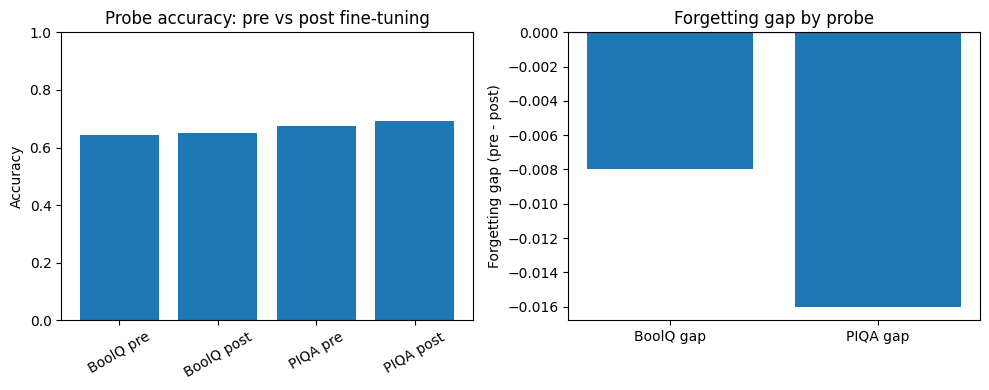

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(
    ["BoolQ pre", "BoolQ post", "PIQA pre", "PIQA post"],
    [boolq_pre["accuracy"], boolq_post["accuracy"], piqa_pre["accuracy"], piqa_post["accuracy"]],
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Probe accuracy: pre vs post fine-tuning")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(["BoolQ gap", "PIQA gap"], [boolq_forgetting_gap, piqa_forgetting_gap])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Forgetting gap (pre - post)")
axes[1].set_title("Forgetting gap by probe")

plt.tight_layout()
plt.show()


## 33. Save Experiment Results

One structured record per run, matching the schema designed to be reused
unchanged by AdaLoRA/DoRA experiments in Phase 2 (`peft_method` is already a
field, not hardcoded to "lora" anywhere else). Saved as both:
- a full per-run JSON file (`{experiment_id}.json`, filename is unique — never overwritten)
- one appended row in a persistent `results.csv` (existing rows are always preserved)


In [34]:
result_record = {
    "experiment_id": experiment_id,
    "timestamp": experiment_timestamp,
    "phase": config.phase,
    "smoke_test": config.smoke_test,
    "base_model": config.base_model_id,
    "peft_method": config.peft_method,
    "seed": config.seed,

    "train_dataset": "samsum",
    "train_samples": len(samsum_train_raw),

    "boolq_samples": len(boolq_examples),
    "piqa_samples": len(piqa_examples),
    "samsum_eval_samples": len(samsum_eval_examples),

    "epochs": config.epochs,
    "per_device_train_batch_size": config.per_device_train_batch_size,
    "gradient_accumulation_steps": config.gradient_accumulation_steps,
    "effective_batch_size": effective_batch_size,
    "learning_rate": config.learning_rate,
    "samsum_max_length": config.samsum_max_length,

    "lora_rank": config.lora_r,
    "lora_alpha": config.lora_alpha,
    "lora_dropout": config.lora_dropout,
    "target_modules": ",".join(config.lora_target_modules),

    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "trainable_percentage": trainable_pct,

    "training_time_seconds": training_time_seconds,
    "peak_gpu_memory_mb": peak_gpu_memory_mb,

    "samsum_pre_rouge1": samsum_pre_scores["rouge1"],
    "samsum_pre_rouge2": samsum_pre_scores["rouge2"],
    "samsum_pre_rougeL": samsum_pre_scores["rougeL"],
    "samsum_post_rouge1": samsum_post_scores["rouge1"],
    "samsum_post_rouge2": samsum_post_scores["rouge2"],
    "samsum_post_rougeL": samsum_post_scores["rougeL"],
    "samsum_rouge1_gain": samsum_rouge1_gain,
    "samsum_rouge2_gain": samsum_rouge2_gain,
    "samsum_rougeL_gain": samsum_rougeL_gain,

    "boolq_pre_accuracy": boolq_pre["accuracy"],
    "boolq_post_accuracy": boolq_post["accuracy"],
    "boolq_forgetting_gap": boolq_forgetting_gap,
    "boolq_majority_class_baseline": boolq_pre["majority_class_baseline"],

    "piqa_pre_accuracy": piqa_pre["accuracy"],
    "piqa_post_accuracy": piqa_post["accuracy"],
    "piqa_forgetting_gap": piqa_forgetting_gap,

    "samsum_source": samsum_source,
    "boolq_source": boolq_source,
    "piqa_source": piqa_source,

    "checkpoint_path": str(adapter_path),
}

json_path = RESULTS_DIR / f"{experiment_id}.json"
json_path.write_text(json.dumps(result_record, indent=2))
print(f"Saved full result record to {json_path}")

csv_path = RESULTS_DIR / "results.csv"
new_row = pd.DataFrame([result_record])
if csv_path.exists():
    existing = pd.read_csv(csv_path)
    combined = pd.concat([existing, new_row], ignore_index=True)
else:
    combined = new_row
combined.to_csv(csv_path, index=False)
print(f"Appended result row to {csv_path} (now {len(combined)} row(s) total)")


Saved full result record to /content/outputs/results/20260816_131240_lora_phase1_proper.json
Appended result row to /content/outputs/results/results.csv (now 1 row(s) total)


## 34. Phase 1 Interpretation and Limitations

**What this run does and does not tell you:**

- This is the first **Phase 1 Proper** run (2,000 SAMSum training examples,
  2 epochs, 500-example BoolQ/PIQA probes, 200-example SAMSum eval) — a much
  larger, more meaningful sample than the smoke test's 100/50/50/20. It is
  the first Phase 1 data point worth actually looking at.
- It is still **one run with one seed**. Per the project's scientific rules,
  no conclusion should be drawn from a single seed — a multi-seed sweep
  (README Week 2, day 9) is required before any claim about forgetting
  magnitude, direction, or significance is defensible. Treat the numbers
  above as "here's what happened once," not "here's the answer."
- Log-likelihood probing has a known confound: fine-tuning on SAMSum shifts
  the model's general output style/genre, which can itself perturb Yes/No or
  Option-1/Option-2 token probabilities in ways unrelated to "knowledge
  forgetting" per se. This is a known, accepted limitation of log-likelihood
  probing, not a bug — worth stating explicitly in any write-up.
- The BoolQ majority-class baseline (printed in Section 20) is there so an
  accuracy number is never read as "reasoning ability" without that context.
- Dataset provenance (`samsum_source`, `boolq_source`, `piqa_source` in the
  saved result record) should be checked — if a fallback mirror was used
  instead of the primary source, note that in any write-up.
- **This notebook covers LoRA only.** AdaLoRA and DoRA are explicitly out of
  scope here — do not read anything above as a comparison against them; no
  such comparison has been run yet.

**What to check after this run finishes:**
- Did every stage run without error, and was there enough T4 headroom (peak
  GPU memory, Section 24 output) — see the runtime/memory estimate given
  alongside this notebook for what to expect before running.
- Do the qualitative SAMSum examples (Section 27) look like genuinely better
  summaries than the smoke test's, or still weak/garbled? With 2,000
  examples and 2 epochs we'd expect a visible step up from the smoke test's
  100-example, 1-epoch summaries.
- Is `boolq_source` / `piqa_source` / `samsum_source` in the saved result
  what you expect (`google/boolq`, `lighteval/piqa`, `knkarthick/samsum` per
  the smoke test's resolved fallbacks)?

**Next step:** results from this run inform (but do not decide by
themselves) what Phase 1 Proper's *final* settings should be, and remain
this project's single-seed LoRA baseline until the multi-seed sweep is run.
AdaLoRA and DoRA are Phase 2 — not started by this notebook.
